# Quality and workload under a frozen small-instance budget

This notebook audits the recorded bounded comparison of QAOA and a shallow VQE ansatz as the input size changes. Training is not repeated during notebook execution. It retains every prescribed run, including missed targets. The run matrix, initialization, sampling schedule, acceptance margin and final-readout budget are fixed before observing results; no best-case reruns or retuning are performed.

The figures report **ideal simulated small-instance behavior**, not a general convergence theorem or evidence of quantum advantage. Measurements are simulated as multinomial counts from explicit circuit probabilities. Those measured counts and descriptive standard errors drive training; exact references are evaluated afterward.

Use the pinned Python 3.12 environment and place the matching **quality-scaling** `optimization.py` and `runs.json` downloads beside this notebook, or run in the source checkout. The generator reproduces the full study in a separate empty output directory; this notebook loads the saved record and checks it independently. Saved outputs serve the static site without a live kernel. The original QAOA and VQE papers supply algorithm context {cite:p}`opt_qaoa2014,opt_vqe2014`; Qiskit core, NumPy and Matplotlib are credited with their pinned releases {cite:p}`opt_qiskit262,opt_numpy254,opt_matplotlib3112`. Our code, exposition and figures are original and MIT-licensed.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import platform
import sys
sys.dont_write_bytecode=True

cwd=Path.cwd().resolve()
candidates=[
    ("recorded checkout quality-scaling snapshot",cwd/"assets/generated/optimization/quality-scaling/optimization.py"),
    ("recorded checkout quality-scaling snapshot",cwd.parent/"assets/generated/optimization/quality-scaling/optimization.py"),
    ("checkout",cwd/"src/openquantum/optimization.py"),
    ("checkout",cwd.parent/"src/openquantum/optimization.py"),
    ("standalone quality-scaling download",cwd/"optimization.py"),
    ("standalone quality-scaling download",cwd/"notebooks/optimization.py"),
]
selected=next(((kind,path.resolve()) for kind,path in candidates if path.is_file()),None)
if selected is None:
    raise FileNotFoundError("Save quality-scaling/optimization.py and runs.json beside this notebook, or run in its source checkout.")
source_kind,module_path=selected
spec=importlib.util.spec_from_file_location("optimization_quality_scaling_notebook_source",module_path)
opt=importlib.util.module_from_spec(spec)
sys.modules[spec.name]=opt
spec.loader.exec_module(opt)
assert Path(opt.__file__).resolve()==module_path
if not hasattr(opt,"run_quality_scaling_demo"):
    raise ImportError("Use the quality-scaling optimization.py download; earlier exports lack this study.")
# Keep the actual source path in the kernel without publishing private directories.
print({"source":source_kind,"implementation_sha256":hashlib.sha256(module_path.read_bytes()).hexdigest(),
       "python":platform.python_version(),
       "packages":{name:importlib.metadata.version(name) for name in ("qiskit","numpy","matplotlib")}})

import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


{'source': 'recorded checkout quality-scaling snapshot', 'implementation_sha256': 'b959c0852ddddcdba4de20dddec2df09bdcd14dae2bd2ef277fde032eab0f392', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}}


## Tasks, circuits and frozen run matrix

For QAOA, the graphs are **paths and cycles** with $n=3,4,5,6,8$ vertices, at $p=1,2$ layers. Each instance uses seeds `7`, `19`, and `41`, giving 60 runs. Every layer starts at $(\gamma_j,\beta_j)=(0.2,0.1)$; parameters are recorded in interleaved layer order. The circuit starts with H on every qubit, uses CX–RZ$(−\gamma_j)$–CX for each edge, and RX$(2\beta_j)$ for mixing. The optimizer minimizes the negative joint cut mean. Its post-run target is exact expected cut divided by the classical maximum, at least **0.80**.

For VQE, $n=2,3,4,6$ and the open-chain Hamiltonian is

$$H=-\sum_{q=0}^{n-1}Z_q+\frac12\sum_{q=0}^{n-2}X_qX_{q+1}.$$

The single ansatz layer applies RY$(\theta_q)$ on every zero-initialized qubit, followed by the chain CX$(0,1)$, CX$(1,2)$, …, CX$(n-2,n-1)$. Every angle starts at 0.6 radians for each of the same three seeds, giving 12 runs. A joint all-Z group scores $-\sum Z_q$; an independent all-X group scores $\tfrac12\sum X_qX_{q+1}$. Group score variances retain covariance of all terms sharing a basis. The post-run target is exact energy-density gap $(E-E_0)/n$ at most **0.05**.

The normalized outputs are different computational tasks, not interchangeable scores. A larger ansatz adds gates and parameters and therefore changes workload; observed quality improvement is not a matched physical resource improvement.


## Frozen measured schedule and final confidence scope

Each run makes an initial call with 128 shots per group, followed by 12 sweeps:

| Sweeps | Coordinate step, radians | Shots per group |
|---|---:|---:|
| 1–4 | 0.4 | 256 |
| 5–8 | 0.2 | 512 |
| 9–12 | 0.1 | 1,024 |

Every sweep re-estimates the incumbent and both displacements along every coordinate. The best sampled proposal is accepted only when its sampled decrease exceeds twice the combined descriptive standard error. The end of the fixed schedule is the only stopping condition. This is a heuristic margin, not a calibrated acceptance probability or convergence certificate.

Each final state receives a **fresh 16,384 shots per measurement group**. There are 72 final estimates and 84 holdout measurement groups. The simultaneous holdout failure allowance **0.05** is split across those 84 groups before running. A separate per-run bound and the simultaneous family bound are both recorded; neither covers the adaptive training trajectory or proves the optimizer reached its target.

The frozen complete workload is **6,408 objective calls**, **7,656 group batches**, and **5,859,840 modeled preparations**: 4,483,584 in training and 1,376,256 in final holdout. These counts include rejected proposals and every fresh incumbent estimate. CPU and size guards keep this a bounded small-instance check; they do not establish affordable larger simulation.


In [2]:
# Load the completed study; do not repeat training or silently regenerate missing data.
import json
record_candidates=[
    module_path.parent/"runs.json",
    cwd/"assets/generated/optimization/quality-scaling/runs.json",
    cwd.parent/"assets/generated/optimization/quality-scaling/runs.json",
    cwd/"runs.json",
]
record_path=next((path.resolve() for path in record_candidates if path.is_file()),None)
if record_path is None:
    raise FileNotFoundError("Download quality-scaling/runs.json with its matching optimization.py; this notebook does not regenerate missing study results.")
study=json.loads(record_path.read_text(encoding="utf-8"))
implementation_sha256=hashlib.sha256(module_path.read_bytes()).hexdigest()
assert study["provenance"]["implementation_sha256"]==implementation_sha256, "The saved study requires its matching executed source snapshot."
assert study["execution_status"]=="completed_ideal_sampled_cpu_study"
assert study["artifact_status"]=="complete"
recipe=study["recipe"]
assert recipe["fixed_published_recipe"]
assert recipe["validation_shots_per_group"]==16384
assert recipe["planned"]["runs"]==72
assert recipe["planned"]["objective_calls"]==6408
assert recipe["planned"]["group_batches"]==7656
assert recipe["planned"]["total_shots"]==5_859_840
assert study["exact_diagnostics_used_for_optimization"] is False
print({"mode":"saved study audit; training not repeated",
       "record_sha256":hashlib.sha256(record_path.read_bytes()).hexdigest(),
       "completed_runs":len(study["summary_rows"]),"training_modeled_preparations":study["training_shots"],
       "final_holdout_modeled_preparations":study["validation_shots"],"total_modeled_preparations":study["total_shots"],
       "recorded_workflow_CPU_wall_seconds":study["workflow_wall_seconds"],
       "recorded_workflow_process_CPU_seconds":study["workflow_process_cpu_seconds"],
       "hardware_feedback_seconds":study["hardware_feedback_seconds"]})


{'mode': 'saved study audit; training not repeated', 'record_sha256': '3eba36c699b660710fcafd957f2426ec8ad8c95bb302b7e91e9af0a7e6da5c36', 'completed_runs': 72, 'training_modeled_preparations': 4483584, 'final_holdout_modeled_preparations': 1376256, 'total_modeled_preparations': 5859840, 'recorded_workflow_CPU_wall_seconds': 4.704194958000016, 'recorded_workflow_process_CPU_seconds': 4.7013869999999995, 'hardware_feedback_seconds': None}


## Independent references and measured-decision replay

The checks below enumerate each graph's cut values independently, construct each chain Hamiltonian as a full small matrix, and reconstruct every measured group mean and variance from counts. They replay all decisions using only sampled estimates and estimated standard errors. Exact state expectations and ground energies are inspected after training, with no influence on accepted moves.

All states use Qiskit's little-endian wire convention. The largest classical reference is bounded by the declared small instances. Numerical references are independent checks of these runs, not formal correctness or general convergence proofs.


In [3]:
cut_cache={}
hamiltonian_cache={}


def independent_cuts(n_qubits,edges):
    if not 2<=n_qubits<=8:
        raise ValueError("independent classical checks are capped at 8 qubits")
    key=(n_qubits,tuple(sorted(tuple(sorted(edge)) for edge in edges)))
    if key not in cut_cache:
        cut_cache[key]=np.array([sum(((z>>u)&1)!=((z>>v)&1) for u,v in edges)
                                 for z in range(1<<n_qubits)],dtype=float)
    return cut_cache[key]


def independent_qaoa_state(n_qubits,edges,parameters):
    values=independent_cuts(n_qubits,edges)
    if len(parameters)%2 or not parameters:
        raise ValueError("QAOA uses interleaved gamma,beta pairs")
    state=np.ones(1<<n_qubits,dtype=complex)/np.sqrt(1<<n_qubits)
    indices=np.arange(1<<n_qubits)
    for gamma,beta in zip(parameters[::2],parameters[1::2]):
        state*=np.exp(-1j*gamma*values)
        for wire in range(n_qubits):
            # Simultaneous amplitudes implement exp(-i beta X) independently.
            state=np.cos(beta)*state-1j*np.sin(beta)*state[indices^(1<<wire)]
    np.testing.assert_allclose(np.vdot(state,state).real,1.,rtol=0,atol=1e-12)
    return state


def independent_chain_hamiltonian(n_qubits):
    if not 2<=n_qubits<=6:
        raise ValueError("these dense VQE checks are limited to declared n<=6 cases")
    if n_qubits not in hamiltonian_cache:
        indices=np.arange(1<<n_qubits)
        z_values=np.array([-sum(1-2*((z>>q)&1) for q in range(n_qubits))
                           for z in indices],dtype=float)
        matrix=np.diag(z_values)
        for q in range(n_qubits-1):
            matrix+=.5*np.eye(1<<n_qubits)[:,indices^((1<<q)|(1<<(q+1)))]
        np.testing.assert_allclose(matrix,matrix.T,rtol=0,atol=1e-14)
        hamiltonian_cache[n_qubits]=(matrix,float(np.linalg.eigvalsh(matrix)[0]))
    return hamiltonian_cache[n_qubits]


def independent_chain_state(n_qubits,parameters):
    if len(parameters)!=n_qubits or not 2<=n_qubits<=6:
        raise ValueError("one RY angle per qubit is required for these declared cases")
    indices=np.arange(1<<n_qubits)
    state=np.zeros(1<<n_qubits,dtype=complex)
    state[0]=1
    for q,theta in enumerate(parameters):
        zeros=indices[(indices&(1<<q))==0]
        ones=zeros^(1<<q)
        before=state.copy()
        state[zeros]=np.cos(theta/2)*before[zeros]-np.sin(theta/2)*before[ones]
        state[ones]=np.sin(theta/2)*before[zeros]+np.cos(theta/2)*before[ones]
    for q in range(n_qubits-1):
        permutation=indices.copy()
        permutation[(indices&(1<<q))!=0]^=1<<(q+1)
        state=state[permutation]
    np.testing.assert_allclose(np.vdot(state,state).real,1.,rtol=0,atol=1e-12)
    return state


def independent_group_scores(algorithm,n_qubits,edges,group_name):
    if algorithm=="qaoa":
        return independent_cuts(n_qubits,edges)
    if group_name=="all_z":
        return np.array([-sum(1-2*((z>>q)&1) for q in range(n_qubits))
                         for z in range(1<<n_qubits)],dtype=float)
    if group_name=="all_x":
        return np.array([.5*sum((1-2*((z>>q)&1))*(1-2*((z>>(q+1))&1)) for q in range(n_qubits-1))
                         for z in range(1<<n_qubits)],dtype=float)
    raise ValueError("unexpected measurement group")


In [4]:
from collections import Counter
run_rows=[]
seen_stream_keys=set()
total_calls=total_groups=total_shots=0
all_gate_counts=Counter()
score_cache={}


def interval_status(algorithm,value,radius):
    if algorithm=="qaoa":
        return "supported" if value-radius>=.80 else "missed" if value+radius<.80 else "inconclusive"
    return "supported" if value+radius<=.05 else "missed" if value-radius>.05 else "inconclusive"


assert len(study["cases"])==24
for case in study["cases"]:
    algorithm=case["algorithm"]
    width=case["n_qubits"]
    edges=tuple(tuple(edge) for edge in case.get("edges",()))
    expected_initial=[x for _ in range(case["p"]) for x in (.2,.1)] if algorithm=="qaoa" else [.6]*width
    np.testing.assert_allclose(case["initial"],expected_initial,rtol=0,atol=1e-14)
    assert [run["seed"] for run in case["runs"]]==[7,19,41]
    groups_per_call=1 if algorithm=="qaoa" else 2
    dimension=len(expected_initial)
    expected_training_calls=1+(1+2*dimension)*12
    expected_training_shots=groups_per_call*(128+(1+2*dimension)*4*(256+512+1024))
    for run in case["runs"]:
        assert run["objective_evaluations"]==expected_training_calls
        assert run["iteration_count"]==12
        assert run["stop_reason"]=="fixed_schedule_exhausted"
        assert run["total_shots"]==expected_training_shots
        assert run["validation"]["total_shots"]==groups_per_call*16384
        assert run["exact_diagnostics_used_for_optimization"] is False
        np.testing.assert_allclose(run["initial"],expected_initial,rtol=0,atol=1e-14)
        weighted=Counter()
        for phase,calls in ((0,run["evaluations"]),(1,[run["validation"]])):
            for call in calls:
                total_calls+=1
                assert call["total_shots"]==sum(g["shots"] for g in call["groups"])
                assert [g["group"] for g in call["groups"]]==case["groups"]
                means,mean_variances=[],[]
                for group in call["groups"]:
                    key=(case["case_id"],group["group"])
                    if key not in score_cache:
                        score_cache[key]=independent_group_scores(algorithm,width,edges,group["group"])
                    scores=score_cache[key]
                    counts=np.zeros(1<<width,dtype=int)
                    for bits,count in group["counts"].items(): counts[int(bits,2)]=count
                    assert counts.sum()==group["shots"]
                    mean=float(counts@scores/group["shots"])
                    variance=float(counts@((scores-mean)**2)/(group["shots"]-1))
                    np.testing.assert_allclose([group["estimate"],group["sample_variance"]],
                                               [mean,variance],rtol=1e-12,atol=1e-12)
                    assert group["outcome_min"]<=scores.min() and group["outcome_max"]>=scores.max()
                    means.append(mean);mean_variances.append(variance/group["shots"])
                    assert group["rng"]["entropy"]==[run["seed"],case["stream_id"]]
                    assert group["rng"]["spawn_key"][0]==phase
                    stream=tuple(group["rng"]["stream_key"])
                    assert stream not in seen_stream_keys
                    seen_stream_keys.add(stream)
                    count_ops={k:v for k,v in group["circuit_gate_counts"].items() if k!="barrier"}
                    if algorithm=="qaoa":
                        expected_ops={"h":width,"rz":len(edges)*case["p"],"rx":width*case["p"],
                                      "cx":2*len(edges)*case["p"],"measure":width}
                    else:
                        expected_ops={"ry":width,"cx":width-1,"measure":width}
                        if group["group"]=="all_x": expected_ops["h"]=width
                    assert count_ops==expected_ops
                    weighted.update({gate:number*group["shots"] for gate,number in count_ops.items()})
                    total_groups+=1;total_shots+=group["shots"]
                signed_mean=-sum(means) if algorithm=="qaoa" else sum(means)
                np.testing.assert_allclose(call["objective_estimate"],signed_mean,rtol=0,atol=1e-11)
                np.testing.assert_allclose(call["estimated_standard_error"],np.sqrt(sum(mean_variances)),rtol=1e-12,atol=1e-12)
        calls=run["evaluations"]
        point=(np.array(expected_initial)+np.pi)%(2*np.pi)-np.pi
        for iteration in run["iterations"]:
            incumbent=calls[iteration["incumbent_evaluation"]]
            proposals=[calls[i] for i in iteration["proposal_evaluations"]]
            assert len(proposals)==2*dimension
            np.testing.assert_allclose(incumbent["parameters"],point,rtol=0,atol=1e-12)
            for proposal in proposals:
                expected=point.copy()
                expected[proposal["axis"]]+=proposal["direction"]*iteration["step"]
                expected=(expected+np.pi)%(2*np.pi)-np.pi
                np.testing.assert_allclose(proposal["parameters"],expected,rtol=0,atol=1e-12)
            best=min(proposals,key=lambda item:item["objective_estimate"])
            margin=2*np.hypot(incumbent["estimated_standard_error"],best["estimated_standard_error"])
            accepted=incumbent["objective_estimate"]-best["objective_estimate"]>margin
            assert accepted==iteration["accepted"]
            assert best["index"]==iteration["best_proposal_evaluation"]
            if accepted: point=np.array(best["parameters"])
            np.testing.assert_allclose(iteration["parameters_after"],point,rtol=0,atol=1e-12)
        np.testing.assert_allclose(run["parameters"],point,rtol=0,atol=1e-12)
        diagnostic=run["diagnostic"]
        parameters=run["parameters"]
        if algorithm=="qaoa":
            values=independent_cuts(width,edges)
            optimum=float(values.max())
            assert diagnostic["classical_optimum"]==optimum
            np.testing.assert_array_equal(diagnostic["cut_values"],values)
            state=independent_qaoa_state(width,edges,parameters)
            raw_quality=float(np.abs(state)**2@values)
            quality=raw_quality/optimum
            denominator=optimum
            exact_met=quality>=.80
            np.testing.assert_allclose(diagnostic["exact_expected_cut"],raw_quality,rtol=0,atol=1e-10)
            np.testing.assert_allclose(diagnostic["exact_approximation_ratio"],quality,rtol=0,atol=1e-10)
        else:
            matrix,ground=independent_chain_hamiltonian(width)
            state=independent_chain_state(width,parameters)
            raw_quality=float(np.vdot(state,matrix@state).real)
            quality=(raw_quality-ground)/width
            denominator=width
            exact_met=quality<=.05
            np.testing.assert_allclose(diagnostic["ground_energy"],ground,rtol=0,atol=1e-11)
            np.testing.assert_allclose(diagnostic["exact_energy"],raw_quality,rtol=0,atol=1e-10)
            np.testing.assert_allclose(diagnostic["energy_density_gap"],quality,rtol=0,atol=1e-10)
        actual=opt.quality_scaling_group_circuit(case,parameters,"all_z").remove_final_measurements(inplace=False)
        actual_state=Statevector.from_instruction(actual).data
        np.testing.assert_allclose(abs(np.vdot(state,actual_state)),1.,rtol=0,atol=1e-10)
        assert run["target_met_audit"]==exact_met
        validation=run["validation"]
        group_delta=.05/84
        global_radius=sum((g["outcome_max"]-g["outcome_min"])*np.sqrt(np.log(2/group_delta)/(2*g["shots"]))
                          for g in validation["groups"])/denominator
        local_delta=.05/len(validation["groups"])
        local_radius=sum((g["outcome_max"]-g["outcome_min"])*np.sqrt(np.log(2/local_delta)/(2*g["shots"]))
                         for g in validation["groups"])/denominator
        estimate=-validation["objective_estimate"]/denominator if algorithm=="qaoa" else (validation["objective_estimate"]-ground)/denominator
        bound=validation["quality_bound"]
        np.testing.assert_allclose([bound["normalized_estimate"],bound["simultaneous_radius"],bound["per_run_95_radius"]],
                                   [estimate,global_radius,local_radius],rtol=0,atol=1e-12)
        assert bound["target_status"]==interval_status(algorithm,estimate,global_radius)
        assert bound["precision_supported"]==(global_radius<=.05)
        all_gate_counts.update(weighted)
        run_rows.append({"case":case,"run":run,"quality":quality,"exact_met":exact_met,
                         "estimate":estimate,"global_radius":global_radius,"local_radius":local_radius,
                         "global_status":bound["target_status"],"local_status":interval_status(algorithm,estimate,local_radius),
                         "global_contains":abs(estimate-quality)<=global_radius,
                         "local_contains":abs(estimate-quality)<=local_radius,
                         "weighted_counts":dict(weighted),"total_shots":run["total_shots_including_validation"]})
assert len(run_rows)==72
assert (total_calls,total_groups,total_shots)==(6408,7656,5_859_840)
assert sum(row["case"]["algorithm"]=="qaoa" for row in run_rows)==60
assert sum(row["case"]["algorithm"]=="vqe" for row in run_rows)==12
print({"reconstructed_objective_calls":total_calls,"reconstructed_group_batches":total_groups,
       "modeled_preparations":total_shots,"replayed_sampled_sweeps":72*12,
       "retained_runs":len(run_rows),"all_simultaneous_precision_radii_at_most_0.05":all(row["global_radius"]<=.05 for row in run_rows)})


{'reconstructed_objective_calls': 6408, 'reconstructed_group_batches': 7656, 'modeled_preparations': 5859840, 'replayed_sampled_sweeps': 864, 'retained_runs': 72, 'all_simultaneous_precision_radii_at_most_0.05': True}


## Achieved quality, including misses

Markers summarize the three prescribed seeds at each input; faint dots show individual outcomes and the vertical ranges are observed minimum-to-maximum ranges, **not confidence intervals**. Every prescribed run is retained. The exact values are post-training diagnostics, separate from the final-readout estimates and intervals.

The QAOA ratio uses the **enumerated classical optimum**, including the smaller optimum of an odd cycle. The VQE gap uses the full matrix ground energy. A restricted ansatz, a short sampled search, and finite shots can all limit achieved quality; this study does not distinguish them by certifying the global optimum over ansatz parameters.


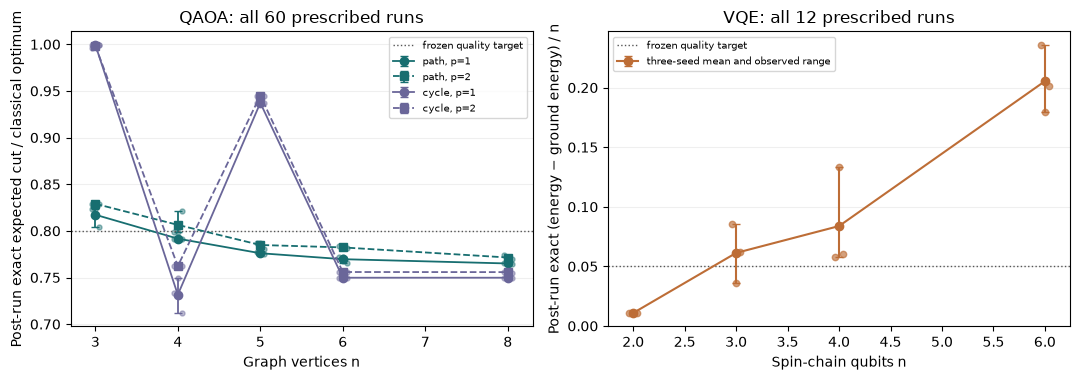

In [5]:
sizes=(3,4,5,6,8)
colors={"path":"#176e70","cycle":"#6a6699","vqe":"#bd6d36"}
fig,axes=plt.subplots(1,2,figsize=(10.9,3.9))
for family in ("path","cycle"):
    for p_depth in (1,2):
        mean_values=[];lower=[];upper=[]
        for width in sizes:
            selected=[row for row in run_rows if row["case"]["algorithm"]=="qaoa" and row["case"]["graph_family"]==family
                      and row["case"]["p"]==p_depth and row["case"]["n_qubits"]==width]
            values=np.array([row["quality"] for row in selected]);mean=float(values.mean())
            mean_values.append(mean);lower.append(max(0.0,float(mean-values.min())));upper.append(max(0.0,float(values.max()-mean)))
            axes[0].scatter(width+np.linspace(-.045,.045,len(values)),values,color=colors[family],alpha=.45,s=13)
        axes[0].errorbar(sizes,mean_values,yerr=[lower,upper],color=colors[family],marker="o" if p_depth==1 else "s",
                         ls="-" if p_depth==1 else "--",capsize=3,lw=1.3,label=f"{family}, p={p_depth}")
axes[0].axhline(.80,color="#555555",ls=":",lw=1,label="frozen quality target")
axes[0].set(xlabel="Graph vertices n",ylabel="Post-run exact expected cut / classical optimum",title="QAOA: all 60 prescribed runs")
axes[0].legend(fontsize=7.5)
v_sizes=(2,3,4,6);means=[];low=[];high=[]
for width in v_sizes:
    selected=[row for row in run_rows if row["case"]["algorithm"]=="vqe" and row["case"]["n_qubits"]==width]
    values=np.array([row["quality"] for row in selected]);mean=float(values.mean())
    means.append(mean);low.append(max(0.0,float(mean-values.min())));high.append(max(0.0,float(values.max()-mean)))
    axes[1].scatter(width+np.linspace(-.04,.04,3),values,color=colors["vqe"],alpha=.65,s=21)
axes[1].errorbar(v_sizes,means,yerr=[low,high],color=colors["vqe"],marker="o",capsize=3,label="three-seed mean and observed range")
axes[1].axhline(.05,color="#555555",ls=":",lw=1,label="frozen quality target")
axes[1].set(xlabel="Spin-chain qubits n",ylabel="Post-run exact (energy − ground energy) / n",title="VQE: all 12 prescribed runs")
axes[1].legend(fontsize=7.5)
for ax in axes:ax.grid(axis="y",alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)


## Complete sampled workload

The left panel reports modeled preparations for **every** objective and final holdout. Increasing QAOA depth or the VQE parameter count changes the number of calls, even though the per-call schedule is unchanged. The right panel weights the actual source CX counts by all those preparations. These are logical protocol counts, not physical gate consumption or hardware runtime.

Rejected proposals, incumbent refreshes, input-state preparation, measurement-basis changes and readout are included. Classical control and reference computations have separate CPU timing. Rotation synthesis, routing, reset and hardware feedback need separate declared models. Existing conditional physical reports remain separate from this logical study.


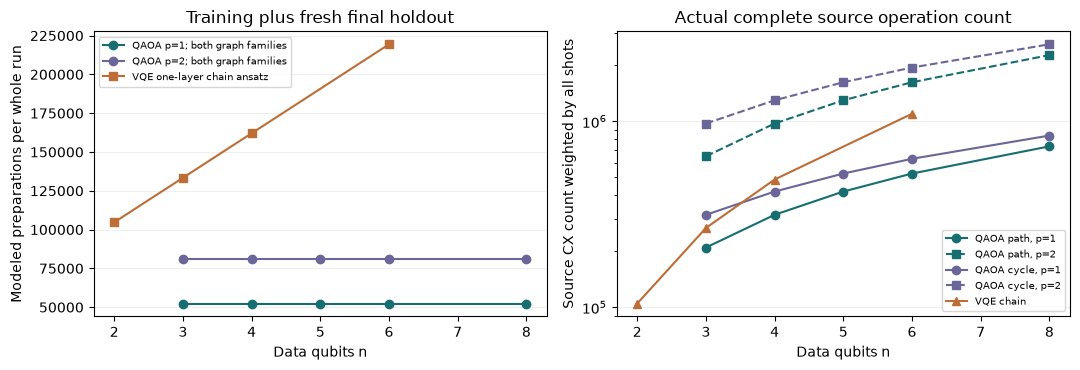

In [6]:
fig,axes=plt.subplots(1,2,figsize=(10.9,3.8))
for p_depth,color in ((1,"#176e70"),(2,"#6a6699")):
    values=[np.mean([row["total_shots"] for row in run_rows if row["case"]["algorithm"]=="qaoa" and row["case"]["p"]==p_depth and row["case"]["n_qubits"]==width]) for width in sizes]
    axes[0].plot(sizes,values,"o-",color=color,label=f"QAOA p={p_depth}; both graph families")
values=[np.mean([row["total_shots"] for row in run_rows if row["case"]["algorithm"]=="vqe" and row["case"]["n_qubits"]==width]) for width in v_sizes]
axes[0].plot(v_sizes,values,"s-",color=colors["vqe"],label="VQE one-layer chain ansatz")
axes[0].set(xlabel="Data qubits n",ylabel="Modeled preparations per whole run",title="Training plus fresh final holdout")
axes[0].ticklabel_format(axis="y",style="plain",useOffset=False)
for family in ("path","cycle"):
    for p_depth in (1,2):
        values=[np.mean([row["weighted_counts"]["cx"] for row in run_rows if row["case"]["algorithm"]=="qaoa" and row["case"]["graph_family"]==family and row["case"]["p"]==p_depth and row["case"]["n_qubits"]==width]) for width in sizes]
        axes[1].plot(sizes,values,marker="o" if p_depth==1 else "s",ls="-" if p_depth==1 else "--",color=colors[family],label=f"QAOA {family}, p={p_depth}")
values=[np.mean([row["weighted_counts"]["cx"] for row in run_rows if row["case"]["algorithm"]=="vqe" and row["case"]["n_qubits"]==width]) for width in v_sizes]
axes[1].plot(v_sizes,values,"^-",color=colors["vqe"],label="VQE chain")
axes[1].set(xlabel="Data qubits n",ylabel="Source CX count weighted by all shots",title="Actual complete source operation count",yscale="log")
for ax in axes:ax.legend(fontsize=7.5);ax.grid(axis="y",alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)


## Final confidence and target support are separate

A bounded-score group of width $W$ with $N$ shots has a Hoeffding radius $W\sqrt{\log(2/\delta)/(2N)}$. For the per-run 95% interval, failure 0.05 is split among that run's groups and their radii are summed. For the simultaneous family interval, failure 0.05 is split among **all 84 final groups** and radii are summed within each objective. VQE energy radii are divided by $n$; QAOA cut radii are divided by the enumerated classical optimum.

The left panel compares these normalized radii. They depend on the known score ranges and frozen shot budget, not on the observed quality. The right panel counts exact post-run target passes and targets supported by the corresponding final intervals. A wider simultaneous interval can be inconclusive even when the exact toy reference passes. These are counts for one frozen experiment, not a population success-rate estimate or a validation of nominal coverage through repeated studies.

Under the stated independent-sampling model, the family bound covers final fixed-state means conditional on the training history. It excludes adaptive training queries, optimizer convergence, physical faults and coherent synthesis errors.


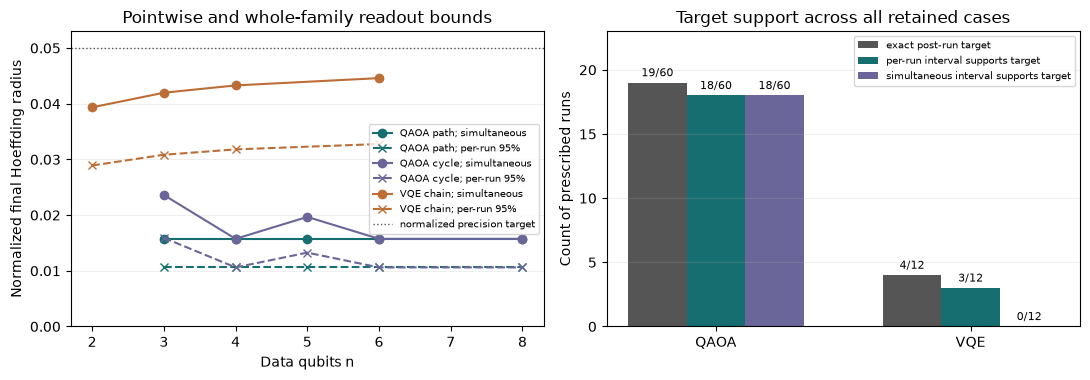

In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,3.9))
for algorithm,family,color,label in (("qaoa","path",colors["path"],"QAOA path"),("qaoa","cycle",colors["cycle"],"QAOA cycle"),("vqe","open-chain",colors["vqe"],"VQE chain")):
    widths=sizes if algorithm=="qaoa" else v_sizes
    globals_,locals_=[] , []
    for width in widths:
        selected=[row for row in run_rows if row["case"]["algorithm"]==algorithm and row["case"]["graph_family"]==family and row["case"]["n_qubits"]==width]
        globals_.append(np.mean([row["global_radius"] for row in selected]));locals_.append(np.mean([row["local_radius"] for row in selected]))
    axes[0].plot(widths,globals_,"o-",color=color,label=label+"; simultaneous")
    axes[0].plot(widths,locals_,"x--",color=color,label=label+"; per-run 95%")
axes[0].axhline(.05,color="#555555",ls=":",lw=1,label="normalized precision target")
axes[0].set(xlabel="Data qubits n",ylabel="Normalized final Hoeffding radius",title="Pointwise and whole-family readout bounds",ylim=(0,.053))
axes[0].legend(fontsize=7)
counts=[]
for algorithm in ("qaoa","vqe"):
    selected=[row for row in run_rows if row["case"]["algorithm"]==algorithm]
    counts.append((sum(row["exact_met"] for row in selected),sum(row["local_status"]=="supported" for row in selected),sum(row["global_status"]=="supported" for row in selected),len(selected)))
x=np.arange(2);bar_width=.23
for offset,color,label,metric in ((-1,"#555555","exact post-run target",0),(0,"#176e70","per-run interval supports target",1),(1,"#6a6699","simultaneous interval supports target",2)):
    bars=axes[1].bar(x+offset*bar_width,[item[metric] for item in counts],bar_width,color=color,label=label)
    for bar,item in zip(bars,counts):axes[1].text(bar.get_x()+bar.get_width()/2,bar.get_height()+.5,f"{item[metric]}/{item[3]}",ha="center",fontsize=8)
axes[1].set(xticks=x,xticklabels=["QAOA","VQE"],ylabel="Count of prescribed runs",title="Target support across all retained cases",ylim=(0,max(item[0] for item in counts)+4))
axes[1].legend(fontsize=7.2)
for ax in axes:ax.grid(axis="y",alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)


## Results and reproducible logical record

The full native MyST summary and downloadable CSV/JSON contain every case and seed. This notebook prints only aggregate counts; all measured traces remain in its `study` object. Target misses and inconclusive intervals remain part of the result. The logical ledger below is separate from any conditional physical report and supplies no certified Clifford+T synthesis or predictive hardware-driven adaptive trajectory.


In [8]:
ledger=opt.quality_scaling_resources(study)
assert ledger["objective_calls"]==6408
assert ledger["group_batches"]==7656
assert ledger["total_preparations"]==5_859_840
assert ledger["validation_groups"]==84
assert ledger["weighted_gate_counts"]==dict(all_gate_counts)
assert ledger["physical_resource_estimate"] is None
for algorithm in ("qaoa","vqe"):
    selected=[row for row in run_rows if row["case"]["algorithm"]==algorithm]
    print({"algorithm":algorithm,"prescribed_runs":len(selected),
           "exact_target_passes":sum(row["exact_met"] for row in selected),
           "retained_exact_target_misses":sum(not row["exact_met"] for row in selected),
           "simultaneous_interval_target_statuses":dict(Counter(row["global_status"] for row in selected)),
           "per_run_intervals_containing_reference":int(sum(row["local_contains"] for row in selected)),
           "simultaneous_intervals_containing_reference":int(sum(row["global_contains"] for row in selected))})
print({"logical_record_objective_calls":ledger["objective_calls"],"logical_record_group_batches":ledger["group_batches"],
       "modeled_preparations":ledger["total_preparations"],"modeled_qubit_readouts":ledger["measured_qubit_readouts"],
       "peak_data_qubits":ledger["logical_peak_qubits"],"hardware_feedback_seconds":ledger["hardware_feedback_seconds"],
       "physical_projection_in_this_logical_record":ledger["physical_resource_estimate"]})
print("Complete frozen-study decisions, independent references, group confidence and source-workload checks passed.")


{'algorithm': 'qaoa', 'prescribed_runs': 60, 'exact_target_passes': 19, 'retained_exact_target_misses': 41, 'simultaneous_interval_target_statuses': {'supported': 18, 'inconclusive': 9, 'missed': 33}, 'per_run_intervals_containing_reference': 60, 'simultaneous_intervals_containing_reference': 60}
{'algorithm': 'vqe', 'prescribed_runs': 12, 'exact_target_passes': 4, 'retained_exact_target_misses': 8, 'simultaneous_interval_target_statuses': {'inconclusive': 8, 'missed': 4}, 'per_run_intervals_containing_reference': 12, 'simultaneous_intervals_containing_reference': 12}
{'logical_record_objective_calls': 6408, 'logical_record_group_batches': 7656, 'modeled_preparations': 5859840, 'modeled_qubit_readouts': 28528896, 'peak_data_qubits': 8, 'hardware_feedback_seconds': None, 'physical_projection_in_this_logical_record': None}
Complete frozen-study decisions, independent references, group confidence and source-workload checks passed.
